In [1]:
import pandas as pd
import json
import ast


# prelim

## Exact Match

In [2]:
from typing import Iterable, Callable, Set, Hashable, Tuple, Any, Optional, List, Dict
from collections import Counter
import re

def strict_exact_match(
    gold: Iterable[Iterable[Any]],
    pred: Iterable[Iterable[Any]],
    normalize: Optional[Callable[[Any], Any]] = None,
) -> Tuple[bool, str]:
    """
    Strict Exact Match for bucketed sequences:
      - Compares two sequences of groups/buckets (e.g., [[A,B],[C],[D,E]]).
      - Bucket order MUST match exactly.
      - Within-bucket order is ignored.
      - Duplicates MUST match (multiset/bag semantics), i.e., counts per item must be equal.

    Args:
        gold: Iterable of buckets (each bucket is an iterable of items).
        pred: Iterable of buckets (each bucket is an iterable of items).
        normalize: Optional normalization function applied to each item
                   before comparison (e.g., str.lower, str.strip).

    Returns:
        (matched, reason)
        matched: True if strictly equal under bucket-as-multiset; else False
        reason:  "" on success; otherwise a brief diagnostic message
    """
    # Materialize as list of lists for safe reuse
    gold_buckets = [list(b) for b in gold]
    pred_buckets = [list(b) for b in pred]

    # 1) Same number of buckets
    if len(gold_buckets) != len(pred_buckets):
        return (False, f"Different # of buckets: gold={len(gold_buckets)} vs pred={len(pred_buckets)}")

    # Normalizer
    norm = (lambda x: normalize(x)) if normalize is not None else (lambda x: x)

    # 2) Compare each bucket as a multiset (counts must match), in order
    for i, (g_b, p_b) in enumerate(zip(gold_buckets, pred_buckets)):
        g_ctr = Counter(norm(x) for x in g_b)
        p_ctr = Counter(norm(x) for x in p_b)
        if g_ctr != p_ctr:
            # Report missing/extra counts explicitly
            missing = g_ctr - p_ctr   # items required but missing counts
            extra   = p_ctr - g_ctr   # items present in pred but not in gold (or too many)
            parts = []
            if missing:
                parts.append(f"missing={dict(sorted(missing.items()))}")
            if extra:
                parts.append(f"extra={dict(sorted(extra.items()))}")
            details = "; ".join(parts) if parts else "bucket mismatch"
            return (False, f"Bucket {i} differs: {details}")

    # 3) All buckets matched
    return (True, "")

In [3]:
# ---- Example ----
gold = [["fever", "headache"], ["rash"], ["fatigue", "nausea"]]
pred = [["rash"],["headache", "fever"], ["nausea", "fatigue"]]
strict_exact_match(gold, pred, normalize=lambda s: s.strip().lower())

(False,
 "Bucket 0 differs: missing={'fever': 1, 'headache': 1}; extra={'rash': 1}")

In [4]:
# ---- Example 1: Normalized match succeeds ----
gold = [["Dose 1", "Dose 2"], ["Observation", "Observation"]]
pred = [["dose 2", " dose 1 "], [" observation ", "Observation"]]
strict_exact_match(gold, pred, normalize=lambda s: s.strip().lower())

(True, '')

In [5]:
# ---- Example 2: Bucket count mismatch ----
gold = [["fever"], ["rash"]]
pred = [["fever"], ["rash"], ["cough"]]
strict_exact_match(gold, pred, normalize=None)

(False, 'Different # of buckets: gold=2 vs pred=3')

In [6]:
# ---- Example 3: Duplicate counts must match ----
gold = [["fever", "fever"], ["rash"]]
pred = [["fever"], ["rash"]]
strict_exact_match(gold, pred, normalize=None)

(False, "Bucket 0 differs: missing={'fever': 1}")

In [7]:
# ---- Example 4: Bucket contents differ ----
gold = [["fever"], ["rash", "cough"]]
pred = [["fever"], ["rash", "hives"]]
strict_exact_match(gold, pred, normalize=None)

(False, "Bucket 1 differs: missing={'cough': 1}; extra={'hives': 1}")

In [8]:
# ------------------ Test Cases ------------------
tests = [
    {
        "name": "1) Perfect match; within-bucket order ignored",
        "gold": [['fever','headache'], ['rash'], ['fatigue','nausea']],
        "pred": [['headache','fever'], ['rash'], ['nausea','fatigue']],
    },
    {
        "name": "2) Different number of buckets",
        "gold": [['fever','headache'], ['rash']],
        "pred": [['fever','headache'], ['rash'], ['fatigue']],
    },
    {
        "name": "3) Extra item in pred (bucket 0)",
        "gold": [['fever','headache'], ['rash']],
        "pred": [['fever','headache','cough'], ['rash']],
    },
    {
        "name": "4) Missing item in pred (bucket 0)",
        "gold": [['fever','headache'], ['rash']],
        "pred": [['fever'], ['rash']],
    },
    {
        "name": "5) Buckets swapped (order mismatch)",
        "gold": [['fever'], ['rash']],
        "pred": [['rash'], ['fever']],
    },
    {
        "name": "6) Duplicates within bucket are ignored",
        "gold": [['fever','fever','headache'], ['rash']],
        "pred": [['headache','fever'], ['rash']],
    },
    {
        "name": "7) Pred has an extra empty bucket",
        "gold": [['fever','headache'], ['rash']],
        "pred": [['fever','headache'], ['rash'], []],
    },
    {
        "name": "8) Segmentation error across buckets",
        "gold": [['fever','headache'], ['rash']],
        "pred": [['fever'], ['headache','rash']],
    },
    {
        "name": "9) Case/whitespace differences handled by normalize",
        "gold": [['Fever',' Headache '], ['RASH']],
        "pred": [['fever','headache'], ['rash']],
    },
]

# ------------------ Run Tests ------------------
for t in tests:
    match, reason = strict_exact_match(t["gold"], t["pred"], normalize=lambda s: s.strip().lower())
    print(f"{t['name']}\n  gold={t['gold']}\n  pred={t['pred']}\n  -> match={match}, reason={reason}\n")


1) Perfect match; within-bucket order ignored
  gold=[['fever', 'headache'], ['rash'], ['fatigue', 'nausea']]
  pred=[['headache', 'fever'], ['rash'], ['nausea', 'fatigue']]
  -> match=True, reason=

2) Different number of buckets
  gold=[['fever', 'headache'], ['rash']]
  pred=[['fever', 'headache'], ['rash'], ['fatigue']]
  -> match=False, reason=Different # of buckets: gold=2 vs pred=3

3) Extra item in pred (bucket 0)
  gold=[['fever', 'headache'], ['rash']]
  pred=[['fever', 'headache', 'cough'], ['rash']]
  -> match=False, reason=Bucket 0 differs: extra={'cough': 1}

4) Missing item in pred (bucket 0)
  gold=[['fever', 'headache'], ['rash']]
  pred=[['fever'], ['rash']]
  -> match=False, reason=Bucket 0 differs: missing={'headache': 1}

5) Buckets swapped (order mismatch)
  gold=[['fever'], ['rash']]
  pred=[['rash'], ['fever']]
  -> match=False, reason=Bucket 0 differs: missing={'fever': 1}; extra={'rash': 1}

6) Duplicates within bucket are ignored
  gold=[['fever', 'fever', 'h

## Group-aware Longest Common Contiguous Subsequence

In [9]:

def group_aware_lccs(
    gold: Iterable[Iterable[Any]],
    pred: Iterable[Iterable[Any]],
    normalize: Optional[Callable[[Any], Any]] = None,
    return_alignment: bool = True,
) -> Tuple[int, float, float, float, Optional[Tuple[Tuple[int,int], Tuple[int,int]]]]:
    """
    Group-aware Longest Common Contiguous Subsequence (LCCS).

    Buckets are treated as sets (order-insensitive inside a bucket).
    We compute the longest block of consecutive buckets that appears in both sequences.

    Returns:
        (lccs_len, recall_gold, precision_pred, f1, alignment)
          - lccs_len: number of buckets in the longest contiguous match
          - recall_gold: lccs_len / max(1, len(gold_tokens))
          - precision_pred: lccs_len / max(1, len(pred_tokens))
          - f1: F1 over bucket-block matching using the above precision/recall
          - alignment: ((g_start, g_end_inclusive), (p_start, p_end_inclusive)) or None
    """
    def canon_bucket(bucket: Iterable[Any]) -> Hashable:
        if normalize is None:
            return frozenset(bucket)
        return frozenset(normalize(x) for x in bucket)

    gold_tokens: List[Hashable] = [canon_bucket(b) for b in gold]
    pred_tokens: List[Hashable] = [canon_bucket(b) for b in pred]
    m, n = len(gold_tokens), len(pred_tokens)

    # dp[i][j] = length of longest common suffix ending at gold[i-1], pred[j-1]
    dp = [[0]*(n+1) for _ in range(m+1)]
    best_len = 0
    best_end_g = 0
    best_end_p = 0

    for i in range(1, m+1):
        gi = gold_tokens[i-1]
        for j in range(1, n+1):
            if gi == pred_tokens[j-1]:
                dp[i][j] = dp[i-1][j-1] + 1
                if dp[i][j] > best_len:
                    best_len = dp[i][j]
                    best_end_g = i
                    best_end_p = j
            else:
                dp[i][j] = 0

    lccs_len = best_len
    recall_gold = lccs_len / max(1, m)
    precision_pred = lccs_len / max(1, n)
    f1 = (2 * recall_gold * precision_pred / (recall_gold + precision_pred)) if (recall_gold + precision_pred) else 0.0

    if not return_alignment or lccs_len == 0:
        return lccs_len, recall_gold, precision_pred, f1, None

    g_start = best_end_g - lccs_len
    g_end   = best_end_g - 1
    p_start = best_end_p - lccs_len
    p_end   = best_end_p - 1
    return lccs_len, recall_gold, precision_pred, f1, ((g_start, g_end), (p_start, p_end))




In [10]:
# ---- Example ----
gold = [["fever","headache"], ["rash"], ["fatigue","nausea"]]
pred = [["headache","fever"], ["cough"], ["rash"], ["nausea","fatigue"]]
l, rg, pp, f1, span = group_aware_lccs(gold, pred, normalize=lambda s: s.strip().lower(), return_alignment=True)
print(l, rg, pp, f1, span)  # -> 2, 2/3, 2/4, ~0.57, ((1,2),(2,3))


2 0.6666666666666666 0.5 0.5714285714285715 ((1, 2), (2, 3))


In [11]:
tests = [
    # 1
    {
        "name": "1) Perfect contiguous match",
        "gold": [['A','B'], ['C'], ['D','E']],
        "pred": [['B','A'], ['C'], ['E','D']],
        "expected_len": 3
    },
    # 2
    {
        "name": "2) Middle bucket mismatch",
        "gold": [['A','B'], ['C'], ['D','E']],
        "pred": [['B','A'], ['X'], ['E','D']],
        "expected_len": 1
    },
    # 3
    {
        "name": "3) Extra bucket inserted but 2-run remains",
        "gold": [['A','B'], ['C'], ['D','E']],
        "pred": [['B','A'], ['C'], ['Y'], ['E','D']],
        "expected_len": 2
    },
    # 4
    {
        "name": "4) Buckets reordered",
        "gold": [['A','B'], ['C'], ['D','E']],
        "pred": [['C'], ['B','A'], ['D','E']],
        "expected_len": 1
    },
    # 5
    {
        "name": "5) No common buckets",
        "gold": [['A','B'], ['C'], ['D','E']],
        "pred": [['X'], ['Y'], ['Z']],
        "expected_len": 0
    },
    # 6
    {
        "name": "6) Two-bucket run at the end",
        "gold": [['A','B'], ['C'], ['D','E']],
        "pred": [['X'], ['B','A'], ['C'], ['Z']],
        "expected_len": 2
    },
    # 7
    {
        "name": "7) Perfect run surrounded by extras",
        "gold": [['A','B'], ['C'], ['D','E']],
        "pred": [['Y'], ['B','A'], ['C'], ['D','E'], ['Z']],
        "expected_len": 3
    },
    # 8
    {
        "name": "8) Split a gold bucket into two predicted buckets",
        "gold": [['A','B'], ['C'], ['D','E']],
        "pred": [['B','A'], ['C'], ['D'], ['E']],
        "expected_len": 2
    },
    # 9
    {
        "name": "9) Merge adjacent gold buckets in prediction",
        "gold": [['A','B'], ['C'], ['D','E']],
        "pred": [['A','B','C'], ['D','E']],
        "expected_len": 1
    },
    # 10
    {
        "name": "10) Case/whitespace differences handled by normalize",
        "gold": [['A','B'], ['C'], ['D','E']],
        "pred": [[' b ',' a '], [' c '], [' d ',' e ']],
        "expected_len": 3
    },
]

# ------------------ Run Tests ------------------
computed_lengths = []
for t in tests:
    l, rg, pp, f1, span = group_aware_lccs(
        t["gold"], t["pred"], normalize=lambda s: str(s).strip().lower(), return_alignment=True
    )
    computed_lengths.append(l)
    status = "PASS" if l == t["expected_len"] else "FAIL"
    print(f"{t['name']} -> LCCS length = {l} (expected {t['expected_len']}) [{status}]")

print("\nComputed LCCS lengths list:")
print(computed_lengths)

1) Perfect contiguous match -> LCCS length = 3 (expected 3) [PASS]
2) Middle bucket mismatch -> LCCS length = 1 (expected 1) [PASS]
3) Extra bucket inserted but 2-run remains -> LCCS length = 2 (expected 2) [PASS]
4) Buckets reordered -> LCCS length = 1 (expected 1) [PASS]
5) No common buckets -> LCCS length = 0 (expected 0) [PASS]
6) Two-bucket run at the end -> LCCS length = 2 (expected 2) [PASS]
7) Perfect run surrounded by extras -> LCCS length = 3 (expected 3) [PASS]
8) Split a gold bucket into two predicted buckets -> LCCS length = 2 (expected 2) [PASS]
9) Merge adjacent gold buckets in prediction -> LCCS length = 1 (expected 1) [PASS]
10) Case/whitespace differences handled by normalize -> LCCS length = 3 (expected 3) [PASS]

Computed LCCS lengths list:
[3, 1, 2, 1, 0, 2, 3, 2, 1, 3]


## Position Error Distance-aware

In [12]:
from collections import defaultdict

def position_error_distance(
    gold: Iterable[Iterable[Any]],
    pred: Iterable[Iterable[Any]],
    normalize: Optional[Callable[[Any], Any]] = None,
    missing_penalty: str = "max",   # "ignore" | "max"
    return_details: bool = False,
) -> Tuple[float, float, Dict[str, Any]]:
    """
    Distance-aware Position Error for bucketed sequences (tie-aware).
    - Assign each item a bucket rank = its bucket index (0-based).
    - Compute absolute bucket-distance for items (ties inside a bucket share rank).
    - Normalize by the maximum possible distance (max(#buckets)-1) to map to [0,1].
    - Optionally penalize missing/extra items with worst-case distance.

    Args:
        gold: sequence of gold buckets, e.g., [["fever","headache"], ["rash"], ["fatigue","nausea"]]
        pred: sequence of predicted buckets
        normalize: optional function to normalize items before comparison (e.g., str.lower)
        missing_penalty: 
            - "ignore": compute over intersection only (no penalty for missing/extra)
            - "max": include union; items missing in one side get worst-case distance
        return_details: if True, returns a details dict with per-item distances and counts

    Returns:
        (score, mae_norm, details)
            score: 1 - mae_norm, clipped to [0,1]  (higher is better)
            mae_norm: normalized mean absolute error in [0,1]
            details: dict with diagnostics if return_details=True, else {}

    Notes:
        - Within-bucket order is ignored (tie-aware).
        - If an item appears in multiple buckets (shouldn't), earliest bucket index is used.
        - If both sequences have only 1 bucket, maximum possible distance is treated as 1 to avoid /0.
    """
    # Helper to normalize an item
    def norm(x: Any) -> Any:
        return x if normalize is None else normalize(x)

    # Map item -> earliest bucket index
    def item_to_rank(seq: Iterable[Iterable[Any]]) -> Dict[Any, int]:
        rank_map: Dict[Any, int] = {}
        for b_idx, bucket in enumerate(seq):
            for x in bucket:
                nx = norm(x)
                # keep earliest occurrence if duplicates across buckets
                if nx not in rank_map:
                    rank_map[nx] = b_idx
        return rank_map

    gold_ranks = item_to_rank(gold)
    pred_ranks = item_to_rank(pred)

    # Determine maximum possible distance between any two bucket ranks
    # B = max(len(list(gold)), len(list(pred)))  # we’ll reuse original iterables shortly; cast once more safely below
    
    # Re-materialize to avoid exhausting iterables
    gold_buckets: List[List[Any]] = [list(b) for b in gold]
    pred_buckets: List[List[Any]] = [list(b) for b in pred]
    B = max(len(gold_buckets), len(pred_buckets))
    max_dist = max(1, B - 1)  # avoid division by zero; if B==1, treat max_dist as 1

    gold_items = set(gold_ranks.keys())
    pred_items = set(pred_ranks.keys())
    inter = gold_items & pred_items
    only_gold = gold_items - pred_items
    only_pred = pred_items - gold_items

    distances: Dict[Any, int] = {}

    # Intersection: real distances
    for x in inter:
        d = abs(pred_ranks[x] - gold_ranks[x])
        distances[x] = d

    # Missing / extra handling
    if missing_penalty == "max":
        # assign worst-case distance to items missing on one side
        for x in only_gold:
            distances[x] = max_dist
        for x in only_pred:
            distances[x] = max_dist
    elif missing_penalty == "ignore":
        pass
    else:
        raise ValueError('missing_penalty must be "ignore" or "max"')

    if len(distances) == 0:
        has_any_gold = any(len(b) > 0 for b in gold_buckets)
        has_any_pred = any(len(b) > 0 for b in pred_buckets)

        # Case A: both sequences empty -> trivially perfect (no displacement possible)
        if not has_any_gold and not has_any_pred:
            score, mae_norm = 1.0, 0.0
            note = "both gold and pred empty; no displacement possible"
        else:
            # Case B: at least one side non-empty but no intersection -> worst score
            score, mae_norm = 0.0, 1.0
            note = "no shared items; intersection-based position treated as worst"

        details = {} if not return_details else {
            "num_gold_buckets": len(gold_buckets),
            "num_pred_buckets": len(pred_buckets),
            "counts": {
                "intersection": 0, 
                "only_gold": len(only_gold), 
                "only_pred": len(only_pred)
                },
            "max_dist": max_dist,
            "mae_raw": score,
            "per_item_distance": {},
            "note": note
        }
        return score, mae_norm, details

    mae = sum(distances.values()) / len(distances)
    mae_norm = min(1.0, mae / max_dist)
    score = max(0.0, 1.0 - mae_norm)

    details = {}
    if return_details:
        details = {
            "num_gold_buckets": len(gold_buckets),
            "num_pred_buckets": len(pred_buckets),
            "counts": {
                "intersection": len(inter),
                "only_gold": len(only_gold),
                "only_pred": len(only_pred),
                "evaluated_items": len(distances)
            },
            "max_dist": max_dist,
            "mae_raw": mae,
            "per_item_distance": dict(sorted(distances.items(), key=lambda kv: (-kv[1], str(kv[0])))),
            "note": None
        }

    return score, mae_norm, details


In [13]:

# ----------------- Example -----------------
gold = [["fever","headache"], ["rash"], ["fatigue","nausea"]]
pred = [["headache","fever"], ["cough"], ["nausea","fatigue"]]
score, mae_norm, info = position_error_distance(
    gold, pred, normalize=lambda s: s.strip().lower(), missing_penalty="max", return_details=True
)
print(score, mae_norm)
print(info)

0.6666666666666667 0.3333333333333333
{'num_gold_buckets': 3, 'num_pred_buckets': 3, 'counts': {'intersection': 4, 'only_gold': 1, 'only_pred': 1, 'evaluated_items': 6}, 'max_dist': 2, 'mae_raw': 0.6666666666666666, 'per_item_distance': {'cough': 2, 'rash': 2, 'fatigue': 0, 'fever': 0, 'headache': 0, 'nausea': 0}, 'note': None}


In [14]:
def run_case(name, gold, pred):
    print(f"\n{name}")
    print("gold:", gold)
    print("pred:", pred)

    s_int, mae_int, d_int = position_error_distance(
        gold, pred, normalize=lambda s: str(s).strip().lower(), missing_penalty="ignore", return_details=True
    )
    print(f"  [intersection] score={s_int:.3f}, mae_norm={mae_int:.3f}, max_dist={d_int['max_dist']} | counts={d_int['counts']} | note = {d_int['note']}")
    print(f"    per-item distances (intersection): {d_int['per_item_distance']}")

    s_uni, mae_uni, d_uni = position_error_distance(
        gold, pred, normalize=lambda s: str(s).strip().lower(), missing_penalty="max", return_details=True
    )
    print(f"  [union]        score={s_uni:.3f}, mae_norm={mae_uni:.3f}, max_dist={d_uni['max_dist']} | counts={d_uni['counts']}| note = {d_int['note']}")
    print(f"    per-item distances (union): {d_uni['per_item_distance']}")


# ------------------ Tests ------------------
gold1 = [["fever","headache"], ["rash"], ["fatigue","nausea"]]
pred1 = [["headache","fever"], ["rash"], ["nausea","fatigue"]]
run_case("Test 1: perfect match", gold1, pred1)

pred2 = [["headache"], ["fever","rash"], ["nausea","fatigue"]]
run_case("Test 2: one item shifted by 1 bucket", gold1, pred2)

pred3 = [["headache"], ["rash"], ["nausea","fatigue","fever"]]
run_case("Test 3: one item shifted by 2 buckets", gold1, pred3)

pred4 = [["headache","fever"], [], ["nausea","fatigue","cough"]]
run_case("Test 4: missing gold item + extra pred item", gold1, pred4)

pred5 = [["headache","fever"], ["rash","cough"], ["nausea","fatigue"]]
run_case("Test 5: extra item only", gold1, pred5)

gold6 = [["a","b"], ["c"], ["d","e"]]
pred6 = [["a","b"], ["d","e"], ["c"]]
run_case("Test 6: swap two buckets", gold6, pred6)

gold7 = [["a","b"], ["c"]]
pred7 = [["a","c"], ["b","c"]]
run_case("Test 7: duplicate in pred (earliest occurrence used)", gold7, pred7)

gold8 = [[" Fever ","Headache "], ["RASH"]]
pred8 = [["fever","headache"], ["rash"]]
run_case("Test 8: normalization check", gold8, pred8)

gold9 = [["a","b","c"]]
pred9 = [["1","2","3","x"]]
run_case("Test 9: single-bucket edge case", gold9, pred9)

gold10 = [["a"], ["b"], ["c"], ["d"]]
pred10 = [["a","b","c","d"]]
run_case("Test 10: different #buckets changes normalization", gold10, pred10)

gold11 = []
pred11 = []
run_case("Test 11: empty for both", gold11, pred11)

# 12: non-empty but no intersection
gold12 = [["a"], ["b"]]
pred12 = [["x"], ["y"]]
run_case("Test 12: non-empty but no intersection", gold12, pred12)

# 13: one empty, one non-empty
gold13 = []
pred13 = [["a"], ["b"]]
run_case("Test 13: one empty, one non-empty", gold13, pred13)




Test 1: perfect match
gold: [['fever', 'headache'], ['rash'], ['fatigue', 'nausea']]
pred: [['headache', 'fever'], ['rash'], ['nausea', 'fatigue']]
  [intersection] score=1.000, mae_norm=0.000, max_dist=2 | counts={'intersection': 5, 'only_gold': 0, 'only_pred': 0, 'evaluated_items': 5} | note = None
    per-item distances (intersection): {'fatigue': 0, 'fever': 0, 'headache': 0, 'nausea': 0, 'rash': 0}
  [union]        score=1.000, mae_norm=0.000, max_dist=2 | counts={'intersection': 5, 'only_gold': 0, 'only_pred': 0, 'evaluated_items': 5}| note = None
    per-item distances (union): {'fatigue': 0, 'fever': 0, 'headache': 0, 'nausea': 0, 'rash': 0}

Test 2: one item shifted by 1 bucket
gold: [['fever', 'headache'], ['rash'], ['fatigue', 'nausea']]
pred: [['headache'], ['fever', 'rash'], ['nausea', 'fatigue']]
  [intersection] score=0.900, mae_norm=0.100, max_dist=2 | counts={'intersection': 5, 'only_gold': 0, 'only_pred': 0, 'evaluated_items': 5} | note = None
    per-item distances 

## Kendall-Tau-b 

In [15]:
import math
from itertools import combinations

def _norm_fn(normalize: Optional[Callable[[Any], Any]]):
    return (lambda x: x) if normalize is None else normalize

def _item_set(seq: Iterable[Iterable[Any]], normalize: Optional[Callable[[Any], Any]]) -> set:
    """All unique items across buckets (order ignored)."""
    norm = _norm_fn(normalize)
    return {norm(x) for bucket in seq for x in bucket}

def _item_ranks(seq: Iterable[Iterable[Any]], normalize: Optional[Callable[[Any], Any]]) -> Dict[Any, int]:
    """
    Map item -> bucket index (rank). Within-bucket order is ignored.
    Assumes no cross-bucket duplicates; if they exist, earliest index wins.
    """
    norm = _norm_fn(normalize)
    ranks: Dict[Any, int] = {}
    for b_idx, bucket in enumerate(seq):
        seen = set()
        for x in bucket:
            k = norm(x)
            if k in seen:   # ignore within-bucket duplicates
                continue
            seen.add(k)
            if k not in ranks:
                ranks[k] = b_idx
    return ranks

# ---------------- Coverage: item set P/R/F1 ----------------

def item_set_prf1(
    gold: Iterable[Iterable[Any]],
    pred: Iterable[Iterable[Any]],
    normalize: Optional[Callable[[Any], Any]] = None,
) -> Tuple[float, float, float, Dict[str, int]]:
    """Coverage only (ignores order)."""
    gold_items = _item_set(gold, normalize)
    pred_items = _item_set(pred, normalize)
    inter = gold_items & pred_items

    precision = len(inter) / len(pred_items) if pred_items else 1.0
    recall    = len(inter) / len(gold_items) if gold_items else 1.0
    f1 = 2 * precision * recall / (precision + recall) if (precision + recall) else 0.0

    details = {
        "gold_count": len(gold_items),
        "pred_count": len(pred_items),
        "intersection": len(inter),
        "only_gold": len(gold_items - pred_items),
        "only_pred": len(pred_items - gold_items),
    }
    return precision, recall, f1, details

# ---------------- Order: tie-aware Kendall’s τ-b (intersection) ----------------

def kendall_tau_b_ties(
    gold: Iterable[Iterable[Any]],
    pred: Iterable[Iterable[Any]],
    normalize: Optional[Callable[[Any], Any]] = None,
    return_details: bool = False,
) -> Tuple[float, Dict[str, Any]]:
    """
    Tie-aware Kendall's τ-b on bucketed sequences.
    - Rank = bucket index; items in same bucket are 'tied'.
    - Only items present in BOTH are compared (pure ordering on intersection).
    """
    gold_r = _item_ranks(gold, normalize)
    pred_r = _item_ranks(pred, normalize)

    items = sorted(gold_r.keys() & pred_r.keys(), key=lambda x: str(x))
    n = len(items)
    if n < 2:
        return 1.0, ({"num_items_intersection": n, "pairs": 0} if return_details else {})

    C = D = T_g = T_p = 0  # concordant, discordant, ties in gold, ties in pred
    disagreements: List[Tuple[Any, Any, int, int]] = []

    for i in range(n):
        a = items[i]
        ga = gold_r[a]; pa = pred_r[a]
        for j in range(i+1, n):
            b = items[j]
            gb = gold_r[b]; pb = pred_r[b]

            # relations: -1 (a before b), 0 (tie), +1 (a after b)
            rg = -1 if ga < gb else (1 if ga > gb else 0)
            rp = -1 if pa < pb else (1 if pa > pb else 0)

            if rg == 0: T_g += 1
            if rp == 0: T_p += 1

            if rg != 0 and rp != 0:
                if rg == rp:
                    C += 1
                else:
                    D += 1
                    if len(disagreements) < 20:
                        disagreements.append((a, b, rg, rp))

    numer = C - D
    denom_left  = C + D + T_g
    denom_right = C + D + T_p
    denom = math.sqrt(denom_left * denom_right) if denom_left > 0 and denom_right > 0 else 0.0
    tau_b = (numer / denom) if denom > 0 else 1.0

    if not return_details:
        return tau_b, {}

    return tau_b, {
        "num_items_intersection": n,
        "pairs": n * (n - 1) // 2,
        "C": C, "D": D, "T_g": T_g, "T_p": T_p,
        "numerator": numer,
        "denominator_parts": {"left": denom_left, "right": denom_right},
        "tau_b": tau_b,
        "sample_disagreements": disagreements,
        "relation_legend": {"-1": "a precedes b", "0": "tie", "+1": "a follows b"},
    }

# ---------------- Optional: combine Order × Coverage ----------------

def combined_order_coverage(
    tau_b: float,
    item_f1: float,
    method: str = "product",   # "product" | "geom" | "weighted_geom"
    weight_tau: float = 0.6,   # only used for "weighted_geom"
    weight_f1: float = 0.4,
) -> float:
    """
    Roll up order (τ-b) and coverage (item F1) into one number in [0,1].
    """
    tau = max(0.0, min(1.0, tau_b))
    f1  = max(0.0, min(1.0, item_f1))
    if method == "product":
        return tau * f1
    if method == "geom":
        return math.sqrt(tau * f1)
    if method == "weighted_geom":
        wsum = max(1e-9, weight_tau + weight_f1)
        # (tau^w1 * f1^w2)^(1/(w1+w2))
        return (tau ** weight_tau) * (f1 ** weight_f1) ** (1.0 / wsum)
    raise ValueError('method must be "product", "geom", or "weighted_geom"')

# ---------------- Convenience wrapper ----------------

def evaluate_order_and_coverage(
    gold: Iterable[Iterable[Any]],
    pred: Iterable[Iterable[Any]],
    normalize: Optional[Callable[[Any], Any]] = None,
    combine: Optional[str] = None,  # None | "product" | "geom" | "weighted_geom"
) -> Dict[str, Any]:
    """
    Returns:
      - tau_b (order on intersection, tie-aware)
      - item_precision, item_recall, item_f1 (coverage)
      - combined (optional)
      - details (diagnostics)
    """
    tau, tau_info = kendall_tau_b_ties(gold, pred, normalize=normalize, return_details=True)
    P, R, F1, cov_info = item_set_prf1(gold, pred, normalize=normalize)

    out = {
        "tau_b": tau,
        "item_precision": P,
        "item_recall": R,
        "item_f1": F1,
        "order_details": tau_info,
        "coverage_details": cov_info,
    }
    if combine:
        out["combined"] = combined_order_coverage(tau, F1, method=combine)
        out["combined_method"] = combine
    return out




In [16]:
# ---------------- Example ----------------
gold = [["Fever","Headache"], ["Rash"], ["Fatigue","Nausea"]]
pred = [["headache","fever"], ["Cough"], ["nausea","fatigue"]]
res = evaluate_order_and_coverage(
    gold, pred, normalize=lambda s: s.strip().lower(), combine="product"
)
print(res)

{'tau_b': 0.6666666666666666, 'item_precision': 0.8, 'item_recall': 0.8, 'item_f1': 0.8000000000000002, 'order_details': {'num_items_intersection': 4, 'pairs': 6, 'C': 4, 'D': 0, 'T_g': 2, 'T_p': 2, 'numerator': 4, 'denominator_parts': {'left': 6, 'right': 6}, 'tau_b': 0.6666666666666666, 'sample_disagreements': [], 'relation_legend': {'-1': 'a precedes b', '0': 'tie', '+1': 'a follows b'}}, 'coverage_details': {'gold_count': 5, 'pred_count': 5, 'intersection': 4, 'only_gold': 1, 'only_pred': 1}, 'combined': 0.5333333333333334, 'combined_method': 'product'}


## evaluation pipeline

In [17]:
# ---------------- Normalization ----------------
def _normalize_default(x: Any) -> str:
    return str(x).strip().lower()

# ---------------- Coercion to buckets ----------------

def _coerce_to_buckets(raw: Any, normalize: Optional[Callable[[Any], Any]] = None) -> List[List[Any]]:
    """
    Convert model outputs into List[List[item]] buckets.
    Handles:
      - list[list[str]]
      - list[str] (single bucket)
      - list[dict] (each dict is a bucket: keys are symptoms; ignore values that are "none"/empty)
      - dict with keys among {'groups','buckets','sequence','timeline','temporal_groups',
                              'ordered_groups','result','temporal_result','output'}
      - JSON string or Python-literal string of any of the above
      - Plain text 'A,B | C | D,E'
    """
    norm = (lambda x: x) if normalize is None else normalize

    def _dedupe_bucket(b: Iterable[Any]) -> List[Any]:
        seen, out = set(), []
        for x in b:
            k = norm(x)
            if k in seen or k == "":
                continue
            seen.add(k)
            out.append(k)
        return out

    def _is_none_val(v: Any) -> bool:
        if v is None: return True
        if isinstance(v, str) and norm(v) == "none": return True
        if isinstance(v, (list, tuple, set, dict)) and len(v) == 0: return True
        return False

    # ---------- STRING INPUT: try JSON, then Python literal, then fallback ----------
    if isinstance(raw, str):
        s = raw.strip()

        # 1) JSON attempt
        if s.startswith("{") or s.startswith("[") or s.startswith("```"):
            try:
                obj = json.loads(s.strip("`"))
                return _coerce_to_buckets(obj, normalize=normalize)
            except Exception:
                # 2) Python literal (handles single quotes)
                try:
                    obj = ast.literal_eval(s)
                    return _coerce_to_buckets(obj, normalize=normalize)
                except Exception:
                    pass

        # 3) Fallback: 'A,B | C | D,E' style
        groups = re.split(r"\|\||\||\n+", s)
        buckets = []
        for g in groups:
            toks = [t.strip() for t in re.split(r"[,\t;]+", g) if t.strip()]
            bk = _dedupe_bucket(toks)
            if bk:
                buckets.append(bk)
        return buckets

    # ---------- PYTHON OBJECTS ----------
    if isinstance(raw, (list, tuple)):
        raw = list(raw)
        if len(raw) == 0:
            return []

        # list of dicts -> each dict is a bucket; keep keys whose values are not "none"/empty
        if all(isinstance(g, dict) for g in raw):
            out = []
            for bucket_obj in raw:
                items = [k for k, v in bucket_obj.items() if not _is_none_val(v)]
                bk = _dedupe_bucket(items)
                if bk:
                    out.append(bk)
            return out

        # list of lists/sets
        if all(isinstance(g, (list, tuple, set)) for g in raw):
            return [_dedupe_bucket(list(g)) for g in raw if len(_dedupe_bucket(list(g))) > 0]

        # list of scalars -> single bucket
        if all(not isinstance(g, (list, tuple, set, dict)) for g in raw):
            b = _dedupe_bucket(raw)
            return [b] if b else []

        # mixed: coerce element-wise
        out = []
        for g in raw:
            if isinstance(g, dict):
                items = [k for k, v in g.items() if not _is_none_val(v)]
                bk = _dedupe_bucket(items)
            elif isinstance(g, (list, tuple, set)):
                bk = _dedupe_bucket(list(g))
            else:
                bk = _dedupe_bucket([g])
            if bk:
                out.append(bk)
        return out

    if isinstance(raw, dict):
        # envelopes
        for key in ["groups","buckets","sequence","timeline","temporal_groups",
                    "ordered_groups","result","temporal_result","output"]:
            if key in raw:
                return _coerce_to_buckets(raw[key], normalize=normalize)
        # dict of symptom->mentions (single bucket)
        items = [k for k, v in raw.items() if not _is_none_val(v)]
        b = _dedupe_bucket(items)
        return [b] if b else []

    # Last resort
    return []


def evaluate_temporal_sample(
    gold_raw: Any,
    pred_raw: Any,
    normalize: Optional[Callable[[Any], Any]] = _normalize_default,
    compute_union_position: bool = True,  # also compute order+coverage position score
    lccs_alignment: bool = True,
    combine_method: Optional[str] = "product",  # None | "product" | "geom" | "weighted_geom"
) -> Dict[str, Any]:
    """
    Parse gold/pred, then compute:
      - Exact Match
      - Item coverage P/R/F1
      - Kendall tau-b (ties) on intersection
      - Position Error (intersection) and (optional) union
      - LCCS (len, Rec_G, Prec_P, F1, alignment)
      - Combined = tau_b x item_F1 (if combine_method is not None)
    """
    gold = _coerce_to_buckets(gold_raw, normalize=normalize)
    pred = _coerce_to_buckets(pred_raw, normalize=normalize)

    # print("Coerced Gold:", gold)
    # print("Coerced Pred:", pred)
    # Exact match
    em_ok, em_reason = strict_exact_match(gold, pred, normalize=normalize)

    # Coverage (items only)
    item_P, item_R, item_F1, cov_details = item_set_prf1(gold, pred, normalize=normalize)

    # Kendall tau-b (ties)
    tau_b, tau_details = kendall_tau_b_ties(gold, pred, normalize=normalize, return_details=True)

    # Position error (intersection-only)
    pos_score_int, pos_mae_norm_int, pos_details_int = position_error_distance(
        gold, pred, normalize=normalize, missing_penalty="ignore", return_details=True
    )
    # Position error (union / order+coverage)
    pos_score_union, pos_mae_norm_union, pos_details_union = None, None, None
    if compute_union_position:
        pos_score_union, pos_mae_norm_union, pos_details_union = position_error_distance(
            gold, pred, normalize=normalize, missing_penalty="max", return_details=True
        )

    # LCCS (contiguous)
    lccs_len, lccs_rec_g, lccs_prec_p, lccs_f1, lccs_align = group_aware_lccs(
        gold, pred, normalize=normalize, return_alignment=lccs_alignment
    )

    # Combined (order x coverage)
    combined = None
    if combine_method is not None:
        # Simple product by default: tau_b * item_F1
        if combine_method == "product":
            combined = tau_b * item_F1
        elif combine_method == "geom":
            combined = (tau_b * item_F1) ** 0.5
        elif combine_method == "weighted_geom":
            # default weights tau:0.6, f1:0.4
            w_tau, w_f1 = 0.6, 0.4
            denom = max(1e-9, w_tau + w_f1)
            combined = ((tau_b ** w_tau) * (item_F1 ** w_f1)) ** (1.0 / denom)
        else:
            raise ValueError("combine_method must be one of: None | 'product' | 'geom' | 'weighted_geom'")

    return {
        "exact_match": {"match": em_ok, "reason": em_reason},
        "coverage": {"precision": item_P, "recall": item_R, "f1": item_F1, "details": cov_details},
        "kendall_tau_b": {"tau_b": tau_b, "details": tau_details},
        "position_error_intersection": {
            "score": pos_score_int, "mae_norm": pos_mae_norm_int, "details": pos_details_int
        },
        "position_error_union": None if pos_score_union is None else {
            "score": pos_score_union, "mae_norm": pos_mae_norm_union, "details": pos_details_union
        },
        "lccs": {
            "length": lccs_len, "recall_gold": lccs_rec_g, "precision_pred": lccs_prec_p,
            "f1": lccs_f1, "alignment": lccs_align
        },
        "combined_order_x_coverage": {"method": combine_method, "score": combined},
        "canonical_inputs": {"gold": gold, "pred": pred},  # after coercion/normalization
    }


# pred_example = results_df.final_result_cleaned.to_list()[0]
# gold_example = sample.llm_result_formatted.to_list()[0]

# # print(pred_example)
# # print(gold_example)

# res = evaluate_temporal_sample(
#     gold_example, pred_example,
#     normalize=lambda s: str(s).strip().lower(),
#     compute_union_position=True,
#     lccs_alignment=True,
#     combine_method="product",  # tau_b * item_F1
# )
# # from pprint import pprint
# # pprint(res)

In [18]:
from typing import Any, Callable, Dict, List, Optional, Tuple

# Assumes these exist from earlier messages:
# - evaluate_temporal_sample(gold_raw, pred_raw, normalize=..., compute_union_position=True, lccs_alignment=True, combine_method="product")

def mean_safe(vals: List[Optional[float]]) -> Optional[float]:
    nums = [v for v in vals if v is not None]
    return sum(nums)/len(nums) if nums else None

def evaluate_temporal_batch(
    gold_list: List[Any],
    pred_list: List[Any],
    normalize: Optional[Callable[[Any], Any]] = lambda s: str(s).strip().lower(),
    compute_union_position: bool = True,
    lccs_alignment: bool = False,     # turn on if you want alignments per sample
    combine_method: Optional[str] = "product",  # None | "product" | "geom" | "weighted_geom"
) -> Dict[str, Any]:
    """
    Evaluate multiple (gold, pred) pairs.
    Returns per-sample metrics and macro/micro averages across all successfully evaluated samples.
    """
    if len(gold_list) != len(pred_list):
        raise ValueError(f"gold_list and pred_list must have same length; got {len(gold_list)} vs {len(pred_list)}")

    per_sample: List[Dict[str, Any]] = []
    n = len(gold_list)

    # Micro-coverage accumulators
    micro_gold_total = 0
    micro_pred_total = 0
    micro_inter_total = 0

    # For macro means
    ems, tau_bs = [], []
    cov_Ps, cov_Rs, cov_F1s = [], [], []
    pos_int_scores, pos_int_maes = [], []
    pos_union_scores, pos_union_maes = [], []
    lccs_lens, lccs_recalls, lccs_precs, lccs_f1s = [], [],[], []
    combined_scores = []

    failures = 0
    # counter = 2

    for idx, (g_raw, p_raw) in enumerate(zip(gold_list, pred_list)):
        try:
            res = evaluate_temporal_sample(
                g_raw, p_raw,
                normalize=normalize,
                compute_union_position=compute_union_position,
                lccs_alignment=lccs_alignment,
                combine_method=combine_method,
            )
            per_sample.append({"index": idx, **res})

            # Exact match rate
            ems.append(1.0 if res["exact_match"]["match"] else 0.0)
            if res["exact_match"]["match"] == True:
                print(f"Sample {idx} exact match!")
            # print('ems: ',ems)
            # Coverage (macro)
            cov = res["coverage"]
            cov_Ps.append(cov["precision"])
            cov_Rs.append(cov["recall"])
            cov_F1s.append(cov["f1"])
            # print('coverage: ',cov_F1s)
            # Coverage (micro)
            cd = cov["details"]
            micro_gold_total += cd["gold_count"]
            micro_pred_total += cd["pred_count"]
            micro_inter_total += cd["intersection"]

            # Kendall tau-b
            tau_bs.append(res["kendall_tau_b"]["tau_b"])
            # print('tau_bs: ',tau_bs)
            # Position error (intersection)
            posi = res["position_error_intersection"]
            pos_int_scores.append(posi["score"])
            pos_int_maes.append(posi["mae_norm"])

            # Position error (union) if present
            if res["position_error_union"] is not None:
                posu = res["position_error_union"]
                pos_union_scores.append(posu["score"])
                pos_union_maes.append(posu["mae_norm"])
                # print('pos_union_scores: ',pos_union_scores)
            # LCCS
            lccs = res["lccs"]
            lccs_lens.append(lccs["length"])
            lccs_recalls.append(lccs["recall_gold"])
            lccs_precs.append(lccs["precision_pred"])
            lccs_f1s.append(lccs["f1"])
            # print('lccs_f1s: ',lccs_f1s)
            
            # Combined
            if res["combined_order_x_coverage"]["score"] is not None:
                combined_scores.append(res["combined_order_x_coverage"]["score"])
            
        except Exception as e:
            failures += 1
            per_sample.append({
                "index": idx,
                "error": str(e),
                "raw_gold": g_raw,
                "raw_pred": p_raw,
            })
            # skip from averages

    evaluated = n - failures

    # Macro averages
    macro = {
        "exact_match_rate": mean_safe(ems),
        "coverage_macro": {
            "precision": mean_safe(cov_Ps),
            "recall":    mean_safe(cov_Rs),
            "f1":        mean_safe(cov_F1s),
        },
        "kendall_tau_b": mean_safe(tau_bs),
        "position_error_intersection": {
            "score":   mean_safe(pos_int_scores),
            "mae_norm":mean_safe(pos_int_maes),
        },
        "position_error_union": None if not pos_union_scores else {
            "score":   mean_safe(pos_union_scores),
            "mae_norm":mean_safe(pos_union_maes),
        },
        "lccs": {
            "length":          mean_safe(lccs_lens),
            "recall_gold":     mean_safe(lccs_recalls),
            "precision_pred":  mean_safe(lccs_precs),
            "f1":              mean_safe(lccs_f1s),
        },
        "combined_order_x_coverage": mean_safe(combined_scores) if combined_scores else None,
    }

    # Micro coverage (sums → single P/R/F1)
    if micro_pred_total == 0 and micro_gold_total == 0:
        micro_cov = {"precision": 1.0, "recall": 1.0, "f1": 1.0,
                     "totals": {"gold": 0, "pred": 0, "intersection": 0}}
    else:
        micro_P = (micro_inter_total / micro_pred_total) if micro_pred_total else 1.0
        micro_R = (micro_inter_total / micro_gold_total) if micro_gold_total else 1.0
        micro_F1 = (2 * micro_P * micro_R / (micro_P + micro_R)) if (micro_P + micro_R) else 0.0
        micro_cov = {
            "precision": micro_P,
            "recall": micro_R,
            "f1": micro_F1,
            "totals": {"gold": micro_gold_total, "pred": micro_pred_total, "intersection": micro_inter_total}
        }

    return {
        "n_samples": n,
        "n_evaluated": evaluated,
        "n_failed": failures,
        "macro_averages": macro,
        "micro_coverage": micro_cov,
        "per_sample": per_sample,
    }




In [19]:
from typing import Any, Optional
def parse_json_best_effort(text: str) -> Optional[Any]:
    if not text:
        return None
    try:
        return json.loads(text)
    except Exception:
        pass
    m = re.search(r"```(?:json)?\s*(\{.*?\}|\[.*?\])\s*```", text, flags=re.S)
    if m:
        try:
            return json.loads(m.group(1))
        except Exception:
            pass
    try:
        lit = ast.literal_eval(text)
        if isinstance(lit, (dict, list)):
            return lit
    except Exception:
        pass
    start = min([p for p in (text.find("{"), text.find("[")) if p != -1], default=-1)
    if start != -1:
        for end in range(len(text) - 1, start, -1):
            if text[end] in "}]":
                chunk = text[start:end + 1]
                try:
                    return json.loads(chunk)
                except Exception:
                    continue
    return None

# prediction run section

In [20]:
# for results from one pass of prediction
pred_name = "claude_plain_results_with_temporal_final.csv"
pred_source = pd.read_csv(pred_name)
# pred_source_final = pd.read_csv("claude_premium_updated_results_with_temporal_final.csv")

# for huggingface models with two parts
# df = pd.read_csv("medgemma_baseline_with_temporal_sample_67_final.csv")
# df0 = pd.read_csv("claude_baseline_with_temporal_example67_part_0.csv")
# df1 = pd.read_csv("claude_baseline_with_temporal_example67_part_100.csv")
# pred_source = pd.concat([df0, df1], ignore_index=True)
# pred_source = df
gold_source = pd.read_csv("openai_gold_with_temporal.csv")



In [21]:
pred_source.head()

,vaers_id,symptom_text,symptom_list,llm_result,llm_result_formatted,final_corrected_version,final_result,no_temporal_info,new_llm_result,final_result_cleaned
0,1420769,"About 4-5 days after my second dose, I began h...","['Chest discomfort', 'Chest pain', 'Electrocar...","[ \n { \n ""Chest pain"": [""non stop chest...","[\n {\n ""Chest pain"": [\n ""non stop c...",NaN,1,False,{'attempts': [{'raw_gen': '```json\n[\n {\n ...,"[\n {\n ""Chest pain"": [\n ""non stop c..."
1,1831772,"Muscle pain, headache, nausea. Muscle pain ins...","['Headache', 'Immediate post-injection reactio...","[\n {\n ""Headache"": [""none""],\n ""Immedi...","[\n {\n ""Myalgia"": [\n ""Muscle pain""\...","[\n {\n ""Myalgia"": [\n ""Muscle pain""\...",0,False,{'attempts': [{'raw_gen': '```json\n[\n {\n ...,"[\n {\n ""Myalgia"": [\n ""Muscle pain i..."
2,1021935,back pain/soreness in his lower back/had bad l...,"['Arthralgia', 'Back pain', 'Nausea', 'Pain in...","[\n {\n ""Vaccination site pain"": [""injecti...","[\n {\n ""Vaccination site pain"": [\n ...",NaN,1,False,{'attempts': [{'raw_gen': '```json\n[\n {\n ...,"[\n {\n ""Vaccination site pain"": [\n ..."
3,2749020,The above vaccines administered without incide...,"['Dizziness', 'Fall', 'Fatigue', 'Head injury'...","[\n {\n ""Syncope"": [""patient fainted""],\n ...","[\n {\n ""Syncope"": [\n ""patient faint...",NaN,1,False,"{'attempts': [{'raw_gen': '```json\n[\n {""Syn...","[\n {\n ""Syncope"": [\n ""patient faint..."
4,940509,"about 4 hrs after vaccination ee had ""tunnel ...","['Dizziness', 'Faeces soft', 'Fatigue', 'Flatu...","[\n {\n ""Tunnel vision"": [""tunnel vision""]...","[\n {\n ""Tunnel vision"": [\n ""tunnel ...",NaN,1,False,{'attempts': [{'raw_gen': '```json\n[\n {\n ...,"[\n {\n ""Tunnel vision"": [\n ""tunnel ..."


In [22]:
gold_source.head()

,vaers_id,symptom_text,symptom_list,llm_result_formatted,final_corrected_version,final_result
0,1420769,"About 4-5 days after my second dose, I began h...","['Chest discomfort', 'Chest pain', 'Electrocar...","[\n {\n ""Chest pain"": [\n ""non stop c...",NaN,1
1,1831772,"Muscle pain, headache, nausea. Muscle pain ins...","['Headache', 'Immediate post-injection reactio...","[\n {\n ""Myalgia"": [\n ""Muscle pain""\...","[\n {\n ""Myalgia"": [\n ""Muscle pain""\...",0
2,1021935,back pain/soreness in his lower back/had bad l...,"['Arthralgia', 'Back pain', 'Nausea', 'Pain in...","[\n {\n ""Vaccination site pain"": [\n ...",NaN,1
3,2749020,The above vaccines administered without incide...,"['Dizziness', 'Fall', 'Fatigue', 'Head injury'...","[\n {\n ""Syncope"": [\n ""patient faint...",NaN,1
4,940509,"about 4 hrs after vaccination ee had ""tunnel ...","['Dizziness', 'Faeces soft', 'Fatigue', 'Flatu...","[\n {\n ""Tunnel vision"": [\n ""tunnel ...",NaN,1


## getting different results for iterations

In [23]:
# res_lst_3 = []
# for row in pred_source.iterrows():
#     len_row = len(row[1]['new_llm_result']['attempts'])
#     if len_row >1:
#         final_result = row[1]['new_llm_result']['attempts'][1]['post_fix']
#     else:
#         final_result = row[1]['new_llm_result']['attempts'][0]['post_fix']
#     # final_result = row[1]['new_llm_result']['attempts'][-1]['post_fix']
 
#     res = json.dumps(final_result, ensure_ascii=False, indent=2)
#     res_lst_3.append(res)

# pred_source['final_result_cleaned'] = res_lst_3
# pred_source.head()
# pred_source.to_csv('openai_our_method_results_with_temporal_final_2_iter.csv', index=False)

In [24]:
# import json, ast
# import pandas as pd

# # --- parse each row's stored result (handles JSON or single-quoted dicts) ---
# def parse_obj(x):
#     if isinstance(x, dict): return x
#     if pd.isna(x): return {}
#     s = str(x)
#     try:
#         return json.loads(s)
#     except Exception:
#         pass
#     try:
#         return ast.literal_eval(s)
#     except Exception:
#         return {}

# def pretty_dump(obj):
#     if obj is None:
#         return None
#     if isinstance(obj, str):
#         # try to parse nested JSON-like strings then dump
#         for parser in (json.loads, ast.literal_eval):
#             try:
#                 obj = parser(obj)
#                 break
#             except Exception:
#                 pass
#     try:
#         return json.dumps(obj, ensure_ascii=False, indent=2)
#     except Exception:
#         return str(obj)

# pred_source["_nlr"] = pred_source["new_llm_result"].apply(parse_obj)
# ID_COL = "vaers_id" if "vaers_id" in pred_source.columns else None

# N_ITERS = 4
# BASE = "openai_vanilla_anchor_updated_results_with_temporal_iter"
# iter_len = []
# for k in range(N_ITERS):  # k = 0..3 -> Iter 1..4
#     vals = []
#     for _, row in pred_source.iterrows():


#         attempts = row["_nlr"].get("attempts", []) if isinstance(row["_nlr"], dict) else []    
#         iter_len.append(len(attempts))
    
#          # get k-th attempt if exists, else last attempt    
#         if isinstance(attempts, list) and k < len(attempts):
#             pf = attempts[k].get("post_fix")
#             vals.append(pretty_dump(pf))
#         else:
#             pf = attempts[-1].get("post_fix") if attempts else None
#             vals.append(pretty_dump(pf))

#     # Build per-iteration dataframe with required column name
#     if ID_COL:
#         out_df = pred_source[[ID_COL]].copy()
#         out_df["final_result_cleaned"] = vals
#     else:
#         out_df = pd.DataFrame({"final_result_cleaned": vals})

#     out_path = f"{BASE}{k+1}.csv"
#     out_df.to_csv(out_path, index=False)
#     print(f"Wrote {out_path} (columns: {list(out_df.columns)})")
#     print(f"Average attempts per row: {sum(iter_len) / len(iter_len) if iter_len else 0}")


In [25]:
pred_source.head()

,vaers_id,symptom_text,symptom_list,llm_result,llm_result_formatted,final_corrected_version,final_result,no_temporal_info,new_llm_result,final_result_cleaned
0,1420769,"About 4-5 days after my second dose, I began h...","['Chest discomfort', 'Chest pain', 'Electrocar...","[ \n { \n ""Chest pain"": [""non stop chest...","[\n {\n ""Chest pain"": [\n ""non stop c...",NaN,1,False,{'attempts': [{'raw_gen': '```json\n[\n {\n ...,"[\n {\n ""Chest pain"": [\n ""non stop c..."
1,1831772,"Muscle pain, headache, nausea. Muscle pain ins...","['Headache', 'Immediate post-injection reactio...","[\n {\n ""Headache"": [""none""],\n ""Immedi...","[\n {\n ""Myalgia"": [\n ""Muscle pain""\...","[\n {\n ""Myalgia"": [\n ""Muscle pain""\...",0,False,{'attempts': [{'raw_gen': '```json\n[\n {\n ...,"[\n {\n ""Myalgia"": [\n ""Muscle pain i..."
2,1021935,back pain/soreness in his lower back/had bad l...,"['Arthralgia', 'Back pain', 'Nausea', 'Pain in...","[\n {\n ""Vaccination site pain"": [""injecti...","[\n {\n ""Vaccination site pain"": [\n ...",NaN,1,False,{'attempts': [{'raw_gen': '```json\n[\n {\n ...,"[\n {\n ""Vaccination site pain"": [\n ..."
3,2749020,The above vaccines administered without incide...,"['Dizziness', 'Fall', 'Fatigue', 'Head injury'...","[\n {\n ""Syncope"": [""patient fainted""],\n ...","[\n {\n ""Syncope"": [\n ""patient faint...",NaN,1,False,"{'attempts': [{'raw_gen': '```json\n[\n {""Syn...","[\n {\n ""Syncope"": [\n ""patient faint..."
4,940509,"about 4 hrs after vaccination ee had ""tunnel ...","['Dizziness', 'Faeces soft', 'Fatigue', 'Flatu...","[\n {\n ""Tunnel vision"": [""tunnel vision""]...","[\n {\n ""Tunnel vision"": [\n ""tunnel ...",NaN,1,False,{'attempts': [{'raw_gen': '```json\n[\n {\n ...,"[\n {\n ""Tunnel vision"": [\n ""tunnel ..."


In [ ]:
# test for sample of 200 + 100
# pred = pred_source.sample(200, random_state=67)
pred = pred_source
# gold = gold_source.sample(n=20, random_state=42)
# align gold to the prediction file by vaers_id (same rows, same order)
gold = gold_source.set_index('vaers_id').loc[pred['vaers_id']].reset_index()
pred_source.info()

In [ ]:
# if final_corrected_version available, use that; otherwise, use llm_result_formatted
gold.info()
gold["final_result_cleaned"] = gold.apply(
    lambda row: row["final_corrected_version"] if pd.notna(row["final_corrected_version"]) else row["llm_result_formatted"],
    axis=1
)
# gold = gold.sample(n=600, random_state=5)
gold.info()
# gold.head()

### getting vaccine ids

In [28]:
# raw annotation data for reference
df_raw = pd.read_csv("o4mini_annotation_final.csv")
df_raw.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6000 entries, 0 to 5999
Data columns (total 27 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   vaers_id                 6000 non-null   int64  
 1   symptom_text             6000 non-null   object 
 2   symptom_list             6000 non-null   object 
 3   llm_result               6000 non-null   object 
 4   llm_result_formatted     6000 non-null   object 
 5   t_result                 6000 non-null   int64  
 6   t_corrected_version      814 non-null    object 
 7   t_category               1337 non-null   object 
 8   t_notes                  440 non-null    object 
 9   h_result                 6000 non-null   int64  
 10  h_corrected_version      188 non-null    object 
 11  h_notes                  615 non-null    object 
 12  final_result             6000 non-null   int64  
 13  final_corrected_version  896 non-null    object 
 14  final_notes             

In [29]:
# sampled data that contains vax type info
df_sample = pd.read_csv("VAERS_Sampled_Data_v4.csv")
df_sample.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6000 entries, 0 to 5999
Data columns (total 11 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   vaers_id         6000 non-null   float64
 1   vax_type         6000 non-null   object 
 2   vax_manu         6000 non-null   object 
 3   age_yrs          5572 non-null   float64
 4   sex              6000 non-null   object 
 5   vax_year         6000 non-null   int64  
 6   symptom_text     6000 non-null   object 
 7   symptom_list     6000 non-null   object 
 8   num_symptoms     6000 non-null   int64  
 9   report_length    6000 non-null   int64  
 10  length_category  6000 non-null   object 
dtypes: float64(2), int64(3), object(6)
memory usage: 515.8+ KB


In [30]:
# check if raw data and sampled data have same number of unique VAERS_ID
print("Raw data unique VAERS_ID:", df_raw.vaers_id.nunique())
print("Sampled data unique VAERS_ID:", df_sample.vaers_id.nunique())
set(df_raw["vaers_id"]) == set(df_sample["vaers_id"])


Raw data unique VAERS_ID: 6000
Sampled data unique VAERS_ID: 6000


True

In [31]:
# check value counts of vax_manu from df_sample
vax_manu_counts = df_sample['vax_manu'].value_counts()
print("Vaccine manu counts in sampled data:")
print(vax_manu_counts)
# get vaers_id to vax_manu mapping
vaersid_to_vaxmanu = dict(zip(df_sample['vaers_id'], df_sample['vax_manu']))
# add vax_manu column to gold
gold['vax_manu'] = gold['vaers_id'].map(vaersid_to_vaxmanu)
# add vax_manu column to pred
pred['vax_manu'] = pred['vaers_id'].map(vaersid_to_vaxmanu)
# check pred and gold vax_manu value counts
print("Gold vax_manu counts:")
print(gold['vax_manu'].value_counts())
print("Pred vax_manu counts:")
print(pred['vax_manu'].value_counts())


Vaccine manu counts in sampled data:
vax_manu
PFIZER\BIONTECH                             2000
MODERNA                                     2000
JANSSEN                                     2000
Name: count, dtype: int64
Gold vax_manu counts:
vax_manu
JANSSEN                                     1159
PFIZER\BIONTECH                             1016
MODERNA                                      981
Name: count, dtype: int64
Pred vax_manu counts:
vax_manu
JANSSEN                                     1159
PFIZER\BIONTECH                             1016
MODERNA                                      981
Name: count, dtype: int64


In [32]:
from pprint import pprint


# get df based on vax_manu for both pred and gold
vax_types = gold['vax_manu'].dropna().unique()
print("Vaccine types in gold data:", vax_types)
for vax in vax_types:
    print(f"\nEvaluating for vaccine type: {vax}")
    gold_vax = gold[gold['vax_manu'] == vax]
    pred_vax = pred[pred['vax_manu'] == vax]
    res = evaluate_temporal_batch(
        gold_vax['final_result_cleaned'].to_list(),
        pred_vax['final_result_cleaned'].to_list(),
        normalize=lambda s: str(s).strip().lower(),
        compute_union_position=True,
        lccs_alignment=False,
        combine_method="product",
    )
    print(f"Results for {vax}:")
    pprint(res["macro_averages"])

Vaccine types in gold data: ['PFIZER\\BIONTECH                         '
 'JANSSEN                                 '
 'MODERNA                                 ']

Evaluating for vaccine type: PFIZER\BIONTECH                         
Sample 1 exact match!
Sample 3 exact match!
Sample 4 exact match!
Sample 6 exact match!
Sample 8 exact match!
Sample 10 exact match!
Sample 12 exact match!
Sample 13 exact match!
Sample 15 exact match!
Sample 18 exact match!
Sample 19 exact match!
Sample 20 exact match!
Sample 26 exact match!
Sample 28 exact match!
Sample 29 exact match!
Sample 30 exact match!
Sample 36 exact match!
Sample 40 exact match!
Sample 42 exact match!
Sample 43 exact match!
Sample 44 exact match!
Sample 45 exact match!
Sample 46 exact match!
Sample 48 exact match!
Sample 50 exact match!
Sample 51 exact match!
Sample 58 exact match!
Sample 59 exact match!
Sample 61 exact match!
Sample 62 exact match!
Sample 67 exact match!
Sample 69 exact match!
Sample 71 exact match!
Sample 73 exa

Sample 430 exact match!
Sample 432 exact match!
Sample 434 exact match!
Sample 435 exact match!
Sample 436 exact match!
Sample 438 exact match!
Sample 440 exact match!
Sample 441 exact match!
Sample 445 exact match!
Sample 446 exact match!
Sample 447 exact match!
Sample 449 exact match!
Sample 450 exact match!
Sample 457 exact match!
Sample 459 exact match!
Sample 465 exact match!
Sample 466 exact match!
Sample 471 exact match!
Sample 473 exact match!
Sample 480 exact match!
Sample 482 exact match!
Sample 484 exact match!
Sample 490 exact match!
Sample 492 exact match!
Sample 493 exact match!
Sample 497 exact match!
Sample 498 exact match!
Sample 502 exact match!
Sample 511 exact match!
Sample 514 exact match!
Sample 518 exact match!
Sample 522 exact match!
Sample 526 exact match!
Sample 528 exact match!
Sample 529 exact match!
Sample 532 exact match!
Sample 535 exact match!
Sample 537 exact match!
Sample 541 exact match!
Sample 543 exact match!
Sample 547 exact match!
Sample 549 exact

In [33]:
pred.head(10)

,vaers_id,symptom_text,symptom_list,llm_result,llm_result_formatted,final_corrected_version,final_result,no_temporal_info,new_llm_result,final_result_cleaned,vax_manu
0,1420769,"About 4-5 days after my second dose, I began h...","['Chest discomfort', 'Chest pain', 'Electrocar...","[ \n { \n ""Chest pain"": [""non stop chest...","[\n {\n ""Chest pain"": [\n ""non stop c...",NaN,1,False,{'attempts': [{'raw_gen': '```json\n[\n {\n ...,"[\n {\n ""Chest pain"": [\n ""non stop c...",PFIZER\BIONTECH
1,1831772,"Muscle pain, headache, nausea. Muscle pain ins...","['Headache', 'Immediate post-injection reactio...","[\n {\n ""Headache"": [""none""],\n ""Immedi...","[\n {\n ""Myalgia"": [\n ""Muscle pain""\...","[\n {\n ""Myalgia"": [\n ""Muscle pain""\...",0,False,{'attempts': [{'raw_gen': '```json\n[\n {\n ...,"[\n {\n ""Myalgia"": [\n ""Muscle pain i...",JANSSEN
2,1021935,back pain/soreness in his lower back/had bad l...,"['Arthralgia', 'Back pain', 'Nausea', 'Pain in...","[\n {\n ""Vaccination site pain"": [""injecti...","[\n {\n ""Vaccination site pain"": [\n ...",NaN,1,False,{'attempts': [{'raw_gen': '```json\n[\n {\n ...,"[\n {\n ""Vaccination site pain"": [\n ...",PFIZER\BIONTECH
3,2749020,The above vaccines administered without incide...,"['Dizziness', 'Fall', 'Fatigue', 'Head injury'...","[\n {\n ""Syncope"": [""patient fainted""],\n ...","[\n {\n ""Syncope"": [\n ""patient faint...",NaN,1,False,"{'attempts': [{'raw_gen': '```json\n[\n {""Syn...","[\n {\n ""Syncope"": [\n ""patient faint...",PFIZER\BIONTECH
4,940509,"about 4 hrs after vaccination ee had ""tunnel ...","['Dizziness', 'Faeces soft', 'Fatigue', 'Flatu...","[\n {\n ""Tunnel vision"": [""tunnel vision""]...","[\n {\n ""Tunnel vision"": [\n ""tunnel ...",NaN,1,False,{'attempts': [{'raw_gen': '```json\n[\n {\n ...,"[\n {\n ""Tunnel vision"": [\n ""tunnel ...",PFIZER\BIONTECH
5,1797468,also had wheezing and would get short of brea...,"['Asthenia', 'Dyspnoea', 'Nasal congestion', '...","[\n {\n ""Asthenia"": [""not much energy""],\n...","[\n {\n ""Asthenia"": [\n ""not much ene...",NaN,1,False,{'attempts': [{'raw_gen': '```json\n[\n {\n ...,"[\n {\n ""Nasal congestion"": [\n ""Had ...",PFIZER\BIONTECH
6,1774261,"Stomach ache, cramps sometimes, after second v...","['Abdominal pain upper', 'Cough', 'Oropharynge...","[\n {\n ""Cough"": [""cough""]\n },\n {\n ...","[\n {\n ""Cough"": [\n ""cough""\n ]\n...",NaN,1,False,"{'attempts': [{'raw_gen': '```json\n{\n ""temp...","[\n {\n ""Cough"": [\n ""Cough, after se...",PFIZER\BIONTECH
7,2107775,loose bowels/diarrhea; bloated and gassy; bloa...,"['Abdominal distension', 'Diarrhoea', 'Flatule...","[\n {\n ""Pain in extremity"": [\n ""sor...","[\n {\n ""Pain in extremity"": [\n ""sor...",NaN,1,False,"{'attempts': [{'raw_gen': '```json\n{\n ""temp...","[\n {\n ""Pain in extremity"": [\n ""sor...",PFIZER\BIONTECH
8,946352,Head felt heavy/full/tingly starting about 6 p...,"['Arthralgia', 'Back pain', 'Chest pain', 'Fat...","[\n {\n ""Head discomfort"": [""Head felt hea...","[\n {\n ""Head discomfort"": [\n ""Head ...",NaN,1,False,{'attempts': [{'raw_gen': '```json\n[\n {\n ...,"[\n {\n ""Head discomfort"": [\n ""Head ...",PFIZER\BIONTECH
9,1263734,Client reports receiving Pfizer COVID 19 vacci...,"['Headache', 'Injection site pain', 'Injection...","[\n {\n ""Injection site pain"": [""sharp pai...","[\n {\n ""Injection site pain"": [\n ""s...",NaN,1,False,{'attempts': [{'raw_gen': '```json\n[\n {\n ...,"[\n {\n ""Injection site pain"": [\n ""s...",PFIZER\BIONTECH


In [34]:
gold.head(10)

,vaers_id,symptom_text,symptom_list,llm_result_formatted,final_corrected_version,final_result,final_result_cleaned,vax_manu
0,1420769,"About 4-5 days after my second dose, I began h...","['Chest discomfort', 'Chest pain', 'Electrocar...","[\n {\n ""Chest pain"": [\n ""non stop c...",NaN,1,"[\n {\n ""Chest pain"": [\n ""non stop c...",PFIZER\BIONTECH
1,1831772,"Muscle pain, headache, nausea. Muscle pain ins...","['Headache', 'Immediate post-injection reactio...","[\n {\n ""Myalgia"": [\n ""Muscle pain""\...","[\n {\n ""Myalgia"": [\n ""Muscle pain""\...",0,"[\n {\n ""Myalgia"": [\n ""Muscle pain""\...",JANSSEN
2,1021935,back pain/soreness in his lower back/had bad l...,"['Arthralgia', 'Back pain', 'Nausea', 'Pain in...","[\n {\n ""Vaccination site pain"": [\n ...",NaN,1,"[\n {\n ""Vaccination site pain"": [\n ...",PFIZER\BIONTECH
3,2749020,The above vaccines administered without incide...,"['Dizziness', 'Fall', 'Fatigue', 'Head injury'...","[\n {\n ""Syncope"": [\n ""patient faint...",NaN,1,"[\n {\n ""Syncope"": [\n ""patient faint...",PFIZER\BIONTECH
4,940509,"about 4 hrs after vaccination ee had ""tunnel ...","['Dizziness', 'Faeces soft', 'Fatigue', 'Flatu...","[\n {\n ""Tunnel vision"": [\n ""tunnel ...",NaN,1,"[\n {\n ""Tunnel vision"": [\n ""tunnel ...",PFIZER\BIONTECH
5,1797468,also had wheezing and would get short of brea...,"['Asthenia', 'Dyspnoea', 'Nasal congestion', '...","[\n {\n ""Asthenia"": [\n ""not much ene...",NaN,1,"[\n {\n ""Asthenia"": [\n ""not much ene...",PFIZER\BIONTECH
6,1774261,"Stomach ache, cramps sometimes, after second v...","['Abdominal pain upper', 'Cough', 'Oropharynge...","[\n {\n ""Cough"": [\n ""cough""\n ]\n...",NaN,1,"[\n {\n ""Cough"": [\n ""cough""\n ]\n...",PFIZER\BIONTECH
7,2107775,loose bowels/diarrhea; bloated and gassy; bloa...,"['Abdominal distension', 'Diarrhoea', 'Flatule...","[\n {\n ""Pain in extremity"": [\n ""sor...",NaN,1,"[\n {\n ""Pain in extremity"": [\n ""sor...",PFIZER\BIONTECH
8,946352,Head felt heavy/full/tingly starting about 6 p...,"['Arthralgia', 'Back pain', 'Chest pain', 'Fat...","[\n {\n ""Head discomfort"": [\n ""Head ...",NaN,1,"[\n {\n ""Head discomfort"": [\n ""Head ...",PFIZER\BIONTECH
9,1263734,Client reports receiving Pfizer COVID 19 vacci...,"['Headache', 'Injection site pain', 'Injection...","[\n {\n ""Injection site pain"": [\n ""s...",NaN,1,"[\n {\n ""Injection site pain"": [\n ""s...",PFIZER\BIONTECH


In [35]:
# check if pred and gold are aligned with the same vaers_id in both dataframes
set(pred["vaers_id"]) == set(gold["vaers_id"])


True

In [36]:
# pred.info()

# # double check data
# check_lst = []
# for row in pred.iterrows():
    
#     # len_row = len(row[1]['new_llm_result']['attempts'])
#     # if len_row >1:
#     #     final_result = row[1]['new_llm_result']['attempts'][1]['post_fix']
#     # else:
#     #     final_result = row[1]['new_llm_result']['attempts'][0]['post_fix']
#     out = row[1]['new_llm_result']
#     parsed_res = parse_json_best_effort(out)
#     print(parsed_res)
#     final_result = parsed_res['attempts'][0]['post_fix']
#     print(final_result)
#     break
#     check_lst.append(final_result)
# pred['final_result_cleaned_1'] = check_lst
# # pred.info()
# #     break
# # gold.llm_result_formatted.to_list()[0]

In [37]:
from pprint import pprint

# Each entry can be list-of-lists, JSON, dicts with 'groups'/'buckets', or simple "A,B | C | D,E" text.
pred_example = pred.final_result_cleaned.to_list()
gold_example = gold.final_result_cleaned.to_list()
# print(pred_example)
# print(gold_example)


summary = evaluate_temporal_batch(
    gold_example, pred_example,
    normalize=lambda s: str(s).strip().lower(),
    compute_union_position=True,
    lccs_alignment=False,
    combine_method="product",
)

pprint(summary['macro_averages'])

Sample 1 exact match!
Sample 2 exact match!
Sample 4 exact match!
Sample 5 exact match!
Sample 7 exact match!
Sample 9 exact match!
Sample 11 exact match!
Sample 13 exact match!
Sample 14 exact match!
Sample 17 exact match!
Sample 20 exact match!
Sample 21 exact match!
Sample 22 exact match!
Sample 24 exact match!
Sample 29 exact match!
Sample 31 exact match!
Sample 32 exact match!
Sample 33 exact match!
Sample 34 exact match!
Sample 41 exact match!
Sample 46 exact match!
Sample 48 exact match!
Sample 49 exact match!
Sample 50 exact match!
Sample 51 exact match!
Sample 52 exact match!
Sample 53 exact match!
Sample 55 exact match!
Sample 57 exact match!
Sample 58 exact match!
Sample 65 exact match!
Sample 66 exact match!
Sample 68 exact match!
Sample 70 exact match!
Sample 75 exact match!
Sample 77 exact match!
Sample 80 exact match!
Sample 82 exact match!
Sample 83 exact match!
Sample 91 exact match!
Sample 92 exact match!
Sample 94 exact match!
Sample 95 exact match!
Sample 100 exact 

In [38]:
n = 66
#225 210
print(pred_example[n])
print(gold_example[n])

[
  {
    "Chest pain": [
      "chest pain"
    ],
    "Fatigue": [
      "was very tired"
    ]
  },
  {
    "Carditis": [
      "heart inflammation"
    ],
    "Troponin increased": [
      "very high troponin numbers"
    ]
  }
]
[
  {
    "Chest pain": [
      "experienced chest pain"
    ],
    "Fatigue": [
      "was very tired"
    ]
  },
  {
    "Carditis": [
      "heart inflammation"
    ],
    "Troponin increased": [
      "very high troponin numbers"
    ]
  }
]


In [39]:
# pred = pred_source_final

print(pred['symptom_text'][n])
print(pred['symptom_list'][n])

My son experienced chest pain and was very tired - Sat 6/19 - I thought normal Sunday 6/20 - seemed normal Monday 6/21 at 11 am severe chest pain.  Taken to hospital - was hospitalized with heart inflammation and very high troponin numbers until Thursday 6/24 - numbers were still elevated but he was allowed to go home since the numbers where on the downward trajectory  Has a follow up apt 7/2 @ 3 pm.
['Carditis', 'Chest pain', 'Fatigue', 'Troponin increased']


In [40]:
# # check actual first, second and third iteration results of pred[n]
# # n = 210
# n = 66
# iter_1 = ast.literal_eval(pred.new_llm_result[n])['attempts'][0]['post_fix']
# iter_1_score = ast.literal_eval(pred.new_llm_result[n])['attempts'][0]['parsed_verify']['score']
# iter_1_fb = ast.literal_eval(pred.new_llm_result[n])['attempts'][0]['parsed_verify']['feedback']
# iter_2 = ast.literal_eval(pred.new_llm_result[n])['attempts'][1]['post_fix']
# iter_2_score = ast.literal_eval(pred.new_llm_result[n])['attempts'][1]['parsed_verify']['score']
# iter_2_fb = ast.literal_eval(pred.new_llm_result[n])['attempts'][1]['parsed_verify']['feedback']
# iter_3 = ast.literal_eval(pred.new_llm_result[n])['attempts'][2]['post_fix']
# iter_3_score = ast.literal_eval(pred.new_llm_result[n])['attempts'][2]['parsed_verify']['score']
# iter_3_fb = ast.literal_eval(pred.new_llm_result[n])['attempts'][2]['parsed_verify']['feedback']
# iter_4 = ast.literal_eval(pred.new_llm_result[n])['attempts'][3]['post_fix']
# iter_4_score = ast.literal_eval(pred.new_llm_result[n])['attempts'][3]['parsed_verify']['score']
# iter_4_fb = ast.literal_eval(pred.new_llm_result[n])['attempts'][3]['parsed_verify']['feedback']
# print("Iter 1:", iter_1)
# print("Iter 1 score:", iter_1_score)
# print("Iter 1 feedback:", iter_1_fb)
# print("Iter 2:", iter_2)
# print("Iter 2 score:", iter_2_score)
# print("Iter 2 feedback:", iter_2_fb)
# print("Iter 3:", iter_3)
# print("Iter 3 score:", iter_3_score)
# print("Iter 3 feedback:", iter_3_fb)
# print("Iter 4:", iter_4)
# print("Iter 4 score:", iter_4_score)
# print("Iter 4 feedback:", iter_4_fb)

### get plot for num_stages

In [41]:
file_map = {
    ('openai',      'zeroshot'):      'openai_baseline_with_temporal_final.csv',
    ('openai',      'reform_anchor'):      'openai_premium_updated_results_final.csv',
    ('openai',      'reform_compass'):      'openai_cascade_vanilla_results_final.csv',
    ('openai',      'inform_anchor'):      'openai_vanilla_anchor_updated_results_with_temporal_final.csv',
    ('openai',      'inform_compass'): 'openai_plain_results_with_temporal_final.csv',

    ('claude',   'zeroshot'):      'claude_baseline_0shot_with_temporal_final.csv',
    ('claude',   'inform_compass'): 'claude_plain_results_with_temporal_final.csv',
    ('claude',      'reform_anchor'):      'claude_premium_updated_results_with_temporal_final.csv',
    ('claude',      'reform_compass'):      'claude_cascade_vanilla_results_with_temporal_final.csv',
    ('claude',      'inform_anchor'):      'claude_vanilla_anchor_updated_results_with_temporal_final.csv',

    ('llama',    'zeroshot'):      'llama3.3_70b_with_temporal_baseline_final.csv',
    ('llama',    'inform_compass'): 'llama70b_plain_with_temporal_final.csv',
    ('llama',      'reform_anchor'):      'llama70b_premium_updated_with_temporal_final.csv',
    ('llama',      'reform_compass'):      'llama70b_cascade_vanilla_with_temporal_final.csv',
    ('llama',      'inform_anchor'):      'llama70b_vanilla_anchor_updated_with_temporal_final.csv',

    ('medgemma', 'zeroshot'):      'medgemma_with_temporal_baseline_final.csv',
    ('medgemma', 'inform_compass'): 'medgemma_plain_with_temporal_final.csv',
    ('medgemma',      'reform_anchor'):      'medgemma_premium_updated_with_temporal_final.csv',
    ('medgemma',      'reform_compass'):      'medgemma_cascade_vanilla_with_temporal_final.csv',
    ('medgemma',      'inform_anchor'):      'medgemma_vanilla_anchor_updated_with_temporal_final.csv',
}


In [42]:
def get_num_stages(x):
    if not x or (isinstance(x, float)):
        return 0
    try:
        parsed = json.loads(x)
    except Exception:
        try:
            parsed = ast.literal_eval(x)
        except Exception:
            return 0
    return sum(
        1 for group in parsed
        if isinstance(group, dict) and any(
            v not in (['none'], 'none') for v in group.values()
        )
    )

df = gold[['vaers_id']].copy()
df['gold_stages'] = gold['final_result_cleaned'].apply(get_num_stages)

# Merge all pred files
for (model, setting), fpath in file_map.items():
    col = f"{model}__{setting}"
    pred = pd.read_csv(fpath)[['vaers_id', 'final_result_cleaned']]
    pred = pred.rename(columns={'final_result_cleaned': col})
    pred[col] = pred[col].apply(get_num_stages)
    df = df.merge(pred, on='vaers_id', how='left')



# stage_df = load_stage_counts(file_map, gold_path='openai_gold_with_temporal.csv')
# stage_df['gold_stages'].value_counts().sort_index()  # print distribution first

In [43]:
df.head()

,vaers_id,gold_stages,openai__zeroshot,openai__reform_anchor,openai__reform_compass,openai__inform_anchor,openai__inform_compass,claude__zeroshot,claude__inform_compass,claude__reform_anchor,...,llama__zeroshot,llama__inform_compass,llama__reform_anchor,llama__reform_compass,llama__inform_anchor,medgemma__zeroshot,medgemma__inform_compass,medgemma__reform_anchor,medgemma__reform_compass,medgemma__inform_anchor
0,1420769,3,2,4,4,4,4,2,3,4,...,3,2,2,2,2,3,3,3,3,3
1,1831772,2,2,2,2,2,2,2,2,2,...,2,2,2,2,2,1,2,3,3,2
2,1021935,2,2,2,2,3,2,2,2,2,...,3,4,3,3,2,4,2,2,2,2
3,2749020,2,2,4,3,4,3,4,4,4,...,5,2,4,4,2,3,7,4,4,7
4,940509,2,2,2,2,2,2,2,2,3,...,2,2,3,3,2,3,3,3,3,3


In [ ]:
df.info(verbose=True)

In [45]:
stage_df = df.copy()

dist = stage_df['gold_stages'].value_counts().sort_index()
print(dist)
print(f"\nCumulative coverage:")
print((dist.cumsum() / dist.sum() * 100).round(1))


gold_stages
2     1207
3      981
4      579
5      225
6      104
7       39
8       12
9        6
10       2
13       1
Name: count, dtype: int64

Cumulative coverage:
gold_stages
2      38.2
3      69.3
4      87.7
5      94.8
6      98.1
7      99.3
8      99.7
9      99.9
10    100.0
13    100.0
Name: count, dtype: float64


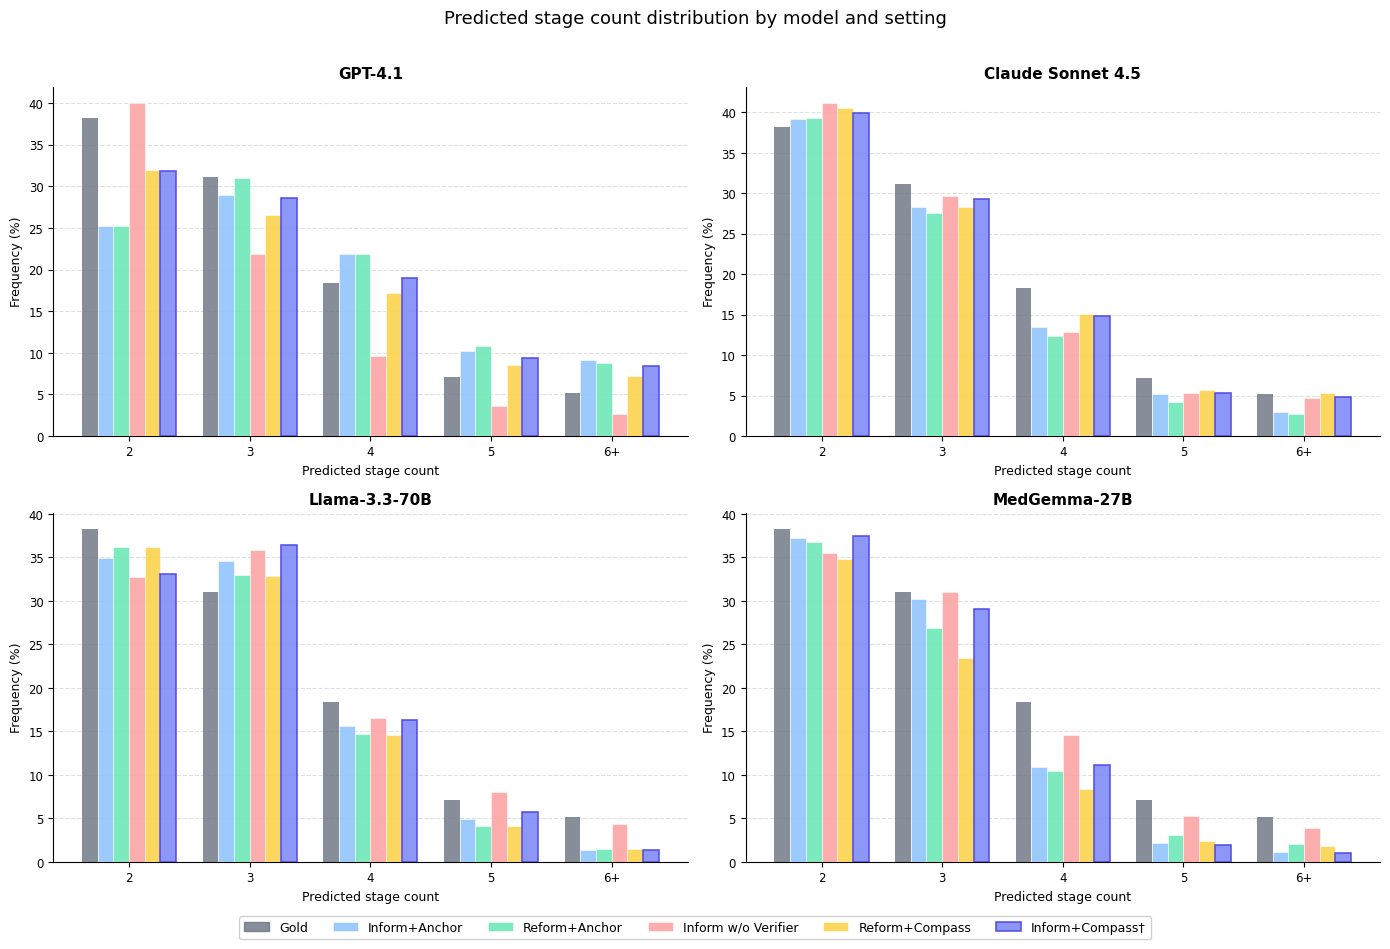

In [46]:
import json
import ast
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import numpy as np

# ── Data loading ──────────────────────────────────────────────────────────────
def get_num_stages(x):
    if not x or (isinstance(x, float)):
        return 0
    try:
        parsed = json.loads(x)
    except Exception:
        try:
            parsed = ast.literal_eval(x)
        except Exception:
            return 0
    return sum(
        1 for group in parsed
        if isinstance(group, dict) and any(
            v not in (['none'], 'none') for v in group.values()
        )
    )

file_map = {
    ('openai',    'zeroshot'):       'openai_baseline_with_temporal_final.csv',
    ('openai',    'reform_anchor'):  'openai_premium_updated_results_final.csv',
    ('openai',    'reform_compass'): 'openai_cascade_vanilla_results_final.csv',
    ('openai',    'inform_anchor'):  'openai_vanilla_anchor_updated_results_with_temporal_final.csv',
    ('openai',    'inform_compass'): 'openai_plain_results_with_temporal_final.csv',
    ('claude',    'zeroshot'):       'claude_baseline_0shot_with_temporal_final.csv',
    ('claude',    'inform_compass'): 'claude_plain_results_with_temporal_final.csv',
    ('claude',    'reform_anchor'):  'claude_premium_updated_results_with_temporal_final.csv',
    ('claude',    'reform_compass'): 'claude_cascade_vanilla_results_with_temporal_final.csv',
    ('claude',    'inform_anchor'):  'claude_vanilla_anchor_updated_results_with_temporal_final.csv',
    ('llama',     'zeroshot'):       'llama3.3_70b_with_temporal_baseline_final.csv',
    ('llama',     'inform_compass'): 'llama70b_plain_with_temporal_final.csv',
    ('llama',     'reform_anchor'):  'llama70b_premium_updated_with_temporal_final.csv',
    ('llama',     'reform_compass'): 'llama70b_cascade_vanilla_with_temporal_final.csv',
    ('llama',     'inform_anchor'):  'llama70b_vanilla_anchor_updated_with_temporal_final.csv',
    ('medgemma',  'zeroshot'):       'medgemma_with_temporal_baseline_final.csv',
    ('medgemma',  'inform_compass'): 'medgemma_plain_with_temporal_final.csv',
    ('medgemma',  'reform_anchor'):  'medgemma_premium_updated_with_temporal_final.csv',
    ('medgemma',  'reform_compass'): 'medgemma_cascade_vanilla_with_temporal_final.csv',
    ('medgemma',  'inform_anchor'):  'medgemma_vanilla_anchor_updated_with_temporal_final.csv',
}

df = gold[['vaers_id']].copy()
df['gold_stages'] = gold['final_result_cleaned'].apply(get_num_stages)
for (model, setting), fpath in file_map.items():
    col = f"{model}__{setting}"
    pred = pd.read_csv(fpath)[['vaers_id', 'final_result_cleaned']]
    pred = pred.rename(columns={'final_result_cleaned': col})
    pred[col] = pred[col].apply(get_num_stages)
    df = df.merge(pred, on='vaers_id', how='left')

# Keep only gold_stages >= 2
stage_df = df[df['gold_stages'] >= 2].copy()

# ── Config ────────────────────────────────────────────────────────────────────
MODELS = {
    'openai':    'GPT-4.1',
    'claude':    'Claude Sonnet 4.5',
    'llama':     'Llama-3.3-70B',
    'medgemma':  'MedGemma-27B',
}

# Settings in paper row order: baselines first, ablations, proposed last
SETTINGS = [
    ('inform_anchor',  'Inform+Anchor'),
    ('reform_anchor',  'Reform+Anchor'),
    ('zeroshot',       'Inform w/o Verifier'),
    ('reform_compass', 'Reform+Compass'),
    ('inform_compass', 'Inform+Compass\u2020'),
]

# One color per series
SERIES_COLORS = {
    'gold':           '#6B7280',
    'inform_anchor':  '#93C5FD',
    'reform_anchor':  '#6EE7B7',
    'zeroshot':       '#FCA5A5',
    'reform_compass': '#FCD34D',
    'inform_compass': '#818CF8',
}

CAP       = 6
x_ticks   = list(range(2, CAP + 1))
x_labels  = [str(i) if i < CAP else f'{CAP}+' for i in x_ticks]
n_series  = 1 + len(SETTINGS)   # gold + 5 = 6
bar_width = 0.13
offsets   = np.linspace(
    -(n_series - 1) / 2 * bar_width,
     (n_series - 1) / 2 * bar_width,
    n_series
)

def compute_freq(col, cap):
    s = stage_df[col].clip(upper=cap)
    counts = s.value_counts().sort_index()
    pct = counts / counts.sum() * 100
    return pct.reindex(range(2, cap + 1), fill_value=0)

# ── Plot ──────────────────────────────────────────────────────────────────────
fig, axes = plt.subplots(2, 2, figsize=(14, 9), sharey=False)
axes = axes.flatten()

for ax_idx, (model_key, model_label) in enumerate(MODELS.items()):
    ax = axes[ax_idx]

    # Gold reference bars
    gold_freq = compute_freq('gold_stages', CAP)
    ax.bar(
        np.array(x_ticks) + offsets[0],
        gold_freq.values,
        width=bar_width,
        color=SERIES_COLORS['gold'],
        alpha=0.80,
        zorder=3,
    )

    # One bar group per setting
    for s_idx, (setting_key, setting_label) in enumerate(SETTINGS):
        col = f"{model_key}__{setting_key}"
        if col not in stage_df.columns:
            continue
        freq      = compute_freq(col, CAP)
        proposed  = setting_key == 'inform_compass'
        ax.bar(
            np.array(x_ticks) + offsets[s_idx + 1],
            freq.values,
            width=bar_width,
            color=SERIES_COLORS[setting_key],
            alpha=0.90,
            edgecolor='#4F46E5' if proposed else 'white',
            linewidth=1.2 if proposed else 0.4,
            zorder=3,
        )

    ax.set_title(model_label, fontsize=11, fontweight='bold')
    ax.set_xticks(x_ticks)
    ax.set_xticklabels(x_labels)
    ax.set_xlabel('Predicted stage count', fontsize=9)
    ax.set_ylabel('Frequency (%)', fontsize=9)
    ax.tick_params(axis='both', labelsize=8.5)
    ax.grid(axis='y', linestyle='--', alpha=0.4, zorder=0)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

# ── Shared legend below figure ────────────────────────────────────────────────
legend_handles = [
    mpatches.Patch(color=SERIES_COLORS['gold'], alpha=0.80, label='Gold')
]
for setting_key, setting_label in SETTINGS:
    proposed = setting_key == 'inform_compass'
    legend_handles.append(
        mpatches.Patch(
            facecolor=SERIES_COLORS[setting_key],
            edgecolor='#4F46E5' if proposed else 'white',
            linewidth=1.2 if proposed else 0.4,
            alpha=0.90,
            label=setting_label,
        )
    )

fig.legend(
    handles=legend_handles,
    loc='lower center',
    ncol=6,
    fontsize=9,
    framealpha=0.9,
    bbox_to_anchor=(0.5, -0.03),
)

fig.suptitle(
    'Predicted stage count distribution by model and setting',
    fontsize=13, y=1.01
)
plt.tight_layout()
# plt.savefig('stage_frequency_histogram.pdf', dpi=300, bbox_inches='tight')
# plt.savefig('stage_frequency_histogram.png', dpi=300, bbox_inches='tight')
plt.show()

In [53]:
import json
import ast
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import numpy as np

# ── Data loading ──────────────────────────────────────────────────────────────
def get_num_stages(x):
    if not x or (isinstance(x, float)):
        return 0
    try:
        parsed = json.loads(x)
    except Exception:
        try:
            parsed = ast.literal_eval(x)
        except Exception:
            return 0
    return sum(
        1 for group in parsed
        if isinstance(group, dict) and any(
            v not in (['none'], 'none') for v in group.values()
        )
    )

file_map = {
    ('openai',    'zeroshot'):       'openai_baseline_with_temporal_final.csv',
    ('openai',    'reform_anchor'):  'openai_premium_updated_results_final.csv',
    ('openai',    'reform_compass'): 'openai_cascade_vanilla_results_final.csv',
    ('openai',    'inform_anchor'):  'openai_vanilla_anchor_updated_results_with_temporal_final.csv',
    ('openai',    'inform_compass'): 'openai_plain_results_with_temporal_final.csv',
    ('claude',    'zeroshot'):       'claude_baseline_0shot_with_temporal_final.csv',
    ('claude',    'inform_compass'): 'claude_plain_results_with_temporal_final.csv',
    ('claude',    'reform_anchor'):  'claude_premium_updated_results_with_temporal_final.csv',
    ('claude',    'reform_compass'): 'claude_cascade_vanilla_results_with_temporal_final.csv',
    ('claude',    'inform_anchor'):  'claude_vanilla_anchor_updated_results_with_temporal_final.csv',
    ('llama',     'zeroshot'):       'llama3.3_70b_with_temporal_baseline_final.csv',
    ('llama',     'inform_compass'): 'llama70b_plain_with_temporal_final.csv',
    ('llama',     'reform_anchor'):  'llama70b_premium_updated_with_temporal_final.csv',
    ('llama',     'reform_compass'): 'llama70b_cascade_vanilla_with_temporal_final.csv',
    ('llama',     'inform_anchor'):  'llama70b_vanilla_anchor_updated_with_temporal_final.csv',
    ('medgemma',  'zeroshot'):       'medgemma_with_temporal_baseline_final.csv',
    ('medgemma',  'inform_compass'): 'medgemma_plain_with_temporal_final.csv',
    ('medgemma',  'reform_anchor'):  'medgemma_premium_updated_with_temporal_final.csv',
    ('medgemma',  'reform_compass'): 'medgemma_cascade_vanilla_with_temporal_final.csv',
    ('medgemma',  'inform_anchor'):  'medgemma_vanilla_anchor_updated_with_temporal_final.csv',
}

df = gold[['vaers_id']].copy()
df['gold_stages'] = gold['final_result_cleaned'].apply(get_num_stages)
for (model, setting), fpath in file_map.items():
    col = f"{model}__{setting}"
    pred = pd.read_csv(fpath)[['vaers_id', 'final_result_cleaned']]
    pred = pred.rename(columns={'final_result_cleaned': col})
    pred[col] = pred[col].apply(get_num_stages)
    df = df.merge(pred, on='vaers_id', how='left')

# Keep only gold_stages >= 2
stage_df = df[df['gold_stages'] >= 2].copy()

# ── Config ────────────────────────────────────────────────────────────────────
import json, ast
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import matplotlib.gridspec as gridspec
import numpy as np

# ── (keep your existing get_num_stages, file_map, df-building, stage_df) ─────

MODELS = {
    'openai':   'GPT-4.1 (a)',
    'claude':   'Claude Sonnet 4.5 (b)',
    'llama':    'Llama-3.3-70B (c)',
    'medgemma': 'MedGemma-27B (d)',
}

SETTINGS = [
    ('inform_anchor',  'PIVOT'),
    ('reform_anchor',  'GUIDE'),
    ('zeroshot',       'CRAFT w/o Verifier'),
    ('reform_compass', 'CRAFT-G'),
    ('inform_compass', 'CRAFT-FULL'),
]

SERIES_COLORS = {
    'gold':           '#6B7280',
    'inform_anchor':  '#93C5FD',
    'reform_anchor':  '#6EE7B7',
    'zeroshot':       '#FCA5A5',
    'reform_compass': '#FCD34D',
    'inform_compass': '#818CF8',
}

# PANEL_LABELS = ['(a)', '(b)', '(c)', '(d)']

CAP       = 6
x_ticks   = list(range(2, CAP + 1))
x_labels  = [str(i) if i < CAP else f'{CAP}+' for i in x_ticks]
n_series  = 1 + len(SETTINGS)
bar_width = 0.13
offsets   = np.linspace(
    -(n_series - 1) / 2 * bar_width,
     (n_series - 1) / 2 * bar_width,
    n_series,
)

def compute_freq(col, cap):
    s = stage_df[col].clip(upper=cap)
    counts = s.value_counts().sort_index()
    pct = counts / counts.sum() * 100
    return pct.reindex(range(2, cap + 1), fill_value=0)

# ── Layout: 2×2 subplots + narrow legend column on the right ─────────────────
# ── Layout: simple 2×2, no legend column ─────────────────────────────────────
fig, axes = plt.subplots(2, 2, figsize=(8, 6))
axes = axes.flatten()

# Build handles once, reuse per subplot
legend_handles = [
    mpatches.Patch(color=SERIES_COLORS['gold'], alpha=0.80, label='Gold')
]
for setting_key, setting_label in SETTINGS:
    proposed = setting_key == 'inform_compass'
    legend_handles.append(
        mpatches.Patch(
            facecolor=SERIES_COLORS[setting_key],
            edgecolor='#4F46E5' if proposed else 'white',
            linewidth=1.2 if proposed else 0.4,
            alpha=0.90,
            label=setting_label,
        )
    )

for ax_idx, (model_key, model_label) in enumerate(MODELS.items()):
    ax = axes[ax_idx]

    gold_freq = compute_freq('gold_stages', CAP)
    ax.bar(
        np.array(x_ticks) + offsets[0],
        gold_freq.values,
        width=bar_width,
        color=SERIES_COLORS['gold'],
        alpha=0.80,
        zorder=3,
    )

    for s_idx, (setting_key, _) in enumerate(SETTINGS):
        col = f"{model_key}__{setting_key}"
        if col not in stage_df.columns:
            continue
        freq     = compute_freq(col, CAP)
        proposed = setting_key == 'inform_compass'
        ax.bar(
            np.array(x_ticks) + offsets[s_idx + 1],
            freq.values,
            width=bar_width,
            color=SERIES_COLORS[setting_key],
            alpha=0.90,
            edgecolor='#4F46E5' if proposed else 'white',
            linewidth=1.2 if proposed else 0.4,
            zorder=3,
        )

    # # Panel label upper-left
    # ax.text(
    #     -0.08, 1.05, PANEL_LABELS[ax_idx],
    #     transform=ax.transAxes,
    #     fontsize=12, fontweight='bold', va='top', ha='left',
    # )

    ax.set_title(model_label, fontsize=9, fontweight='bold', pad=4)
    ax.set_xticks(x_ticks)
    ax.set_xticklabels(x_labels, fontsize=12)
    ax.set_xlabel('Predicted stage count', fontsize=11)
    ax.set_ylabel('Frequency (%)',          fontsize=11)
    ax.tick_params(axis='both', labelsize=12)
    ax.grid(axis='y', linestyle='--', alpha=0.4, zorder=0)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

    # ── Per-subplot legend ────────────────────────────────────────────────────
    ax.legend(
        handles=legend_handles,
        loc='upper right',
        fontsize=9,
        framealpha=0.85,
        handlelength=1.0,
        handleheight=0.8,
        borderpad=0.4,
        labelspacing=0.35,
        handletextpad=0.4,
    )

plt.tight_layout(pad=1.2)
plt.savefig('stage_frequency_histogram.pdf', dpi=300, bbox_inches='tight')
plt.savefig('stage_frequency_histogram.png', dpi=300, bbox_inches='tight')
plt.close()

### final results

In [47]:
from medtempo_eval import MedTempoEvaluator

evaluator = MedTempoEvaluator()

out = evaluator.evaluate_batch(
    gold_list = gold_example,
    pred_list = pred_example,
)


pprint(out['macro_averages'])


{'combined_order_x_coverage': 0.5493981796263457,
 'coverage_macro': {'f1': 0.9450280863861932,
                    'precision': 0.9991718973182852,
                    'recall': 0.9203830569301593},
 'exact_match_rate': 0.37135614702154623,
 'kendall_tau_b': 0.5907402121143196,
 'lccs': {'f1': 0.6160030743824425,
          'length': 1.8833967046894804,
          'precision_pred': 0.6488022310740925,
          'recall_gold': 0.5975980952929607},
 'position_error_intersection': {'mae_norm': 0.1273938317891065,
                                 'score': 0.8726061682108941},
 'position_error_union': {'mae_norm': 0.18189288623461025,
                          'score': 0.8181071137653908}}
